**Notebook for an overview and examples**

Project summary :

Next-OSO project consists of imporving the current soil occupation OSO product by exploring Deep Learning architectures and Foundation models embedding.

This notebook aims to give an overview of the project and give examples to on how to use the main functions. 

Before going through, read the README.md file. 

## Next-OSO dataset

In [ ]:
from data_functions import dataset, plot_functions

# Create Nextoso dataset object
path_to_nextoso_data = "/home/hkerino/Documents/nextoso-dataset/data/10m"
data = dataset.next_oso_Dataset(path_data=path_to_nextoso_data)
print(f"Number of samples in the dataset: {len(data)}")

# Create Nextoso dataset object for a specific fold
data_one_fold = dataset.next_oso_Dataset(path_data=path_to_nextoso_data, folds=[1])
print(f"Number of samples in the dataset: {len(data_one_fold)}")

Number of samples in the dataset: 3598
Number of samples in the dataset: 723


In [3]:
# Load a sample, 2 possibilities: by index or by sample name
sample_1 = data.__getitem__(0)
sample_2 = data.__getitem__("0404")

inputs, labels = sample_1
print(f"inputs list length : {len(inputs)} => (S2, dates, masks, geodatas)\n")

print(f"Labels shape : {labels.shape}\n")

print(
    "Inputs shapes :\n"
    f"sample S2 shape : {inputs[0].shape} # (C,T,H,W)\n"
    f"dates shape     : {inputs[1].shape} # (T)\n"
    f"masks           : {inputs[2]}\n"
    f"geodatas shape  : {inputs[3].shape} # (D, H, W) \n"
)

inputs list length : 4 => (S2, dates, masks, geodatas)

Labels shape : torch.Size([128, 128])

Inputs shapes :
sample S2 shape : torch.Size([10, 54, 128, 128]) # (C,T,H,W)
dates shape     : torch.Size([54]) # (T)
masks           : None
geodatas shape  : torch.Size([4, 128, 128]) # (D, H, W) 



In [4]:
# By default S2 mask is not returned and geodatas is. Can be control
data_new = dataset.next_oso_Dataset(
    path_data=path_to_nextoso_data, use_mnt_data=False, mask_needed=True
)
sample_3 = data_new.__getitem__(0)
print(f"masks     : {sample_3[0][2].shape}\ngeodatas  : {sample_3[0][3]}")

masks     : torch.Size([54, 128, 128])
geodatas  : None


In [110]:
# plots
data_plot = dataset.next_oso_Dataset(
    path_data=path_to_nextoso_data, use_mnt_data=True, mask_needed=True
)

ID = "0053"
inputs, label = data_plot.__getitem__(ID)

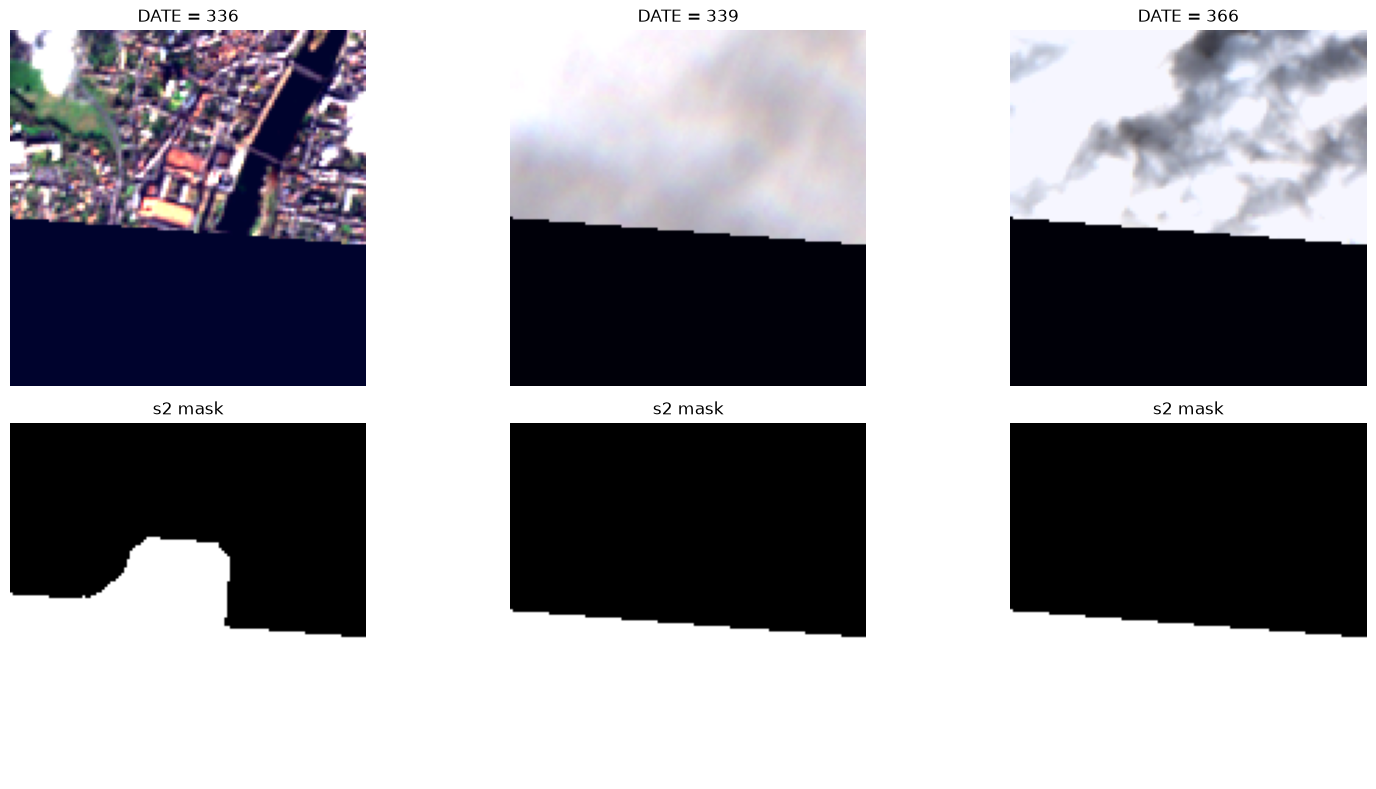

In [111]:
# S2 and masks
plot_functions.plot_s2_and_mask(
    s2=inputs[0], dates=inputs[1], masks=inputs[2], start_timestep=58
)

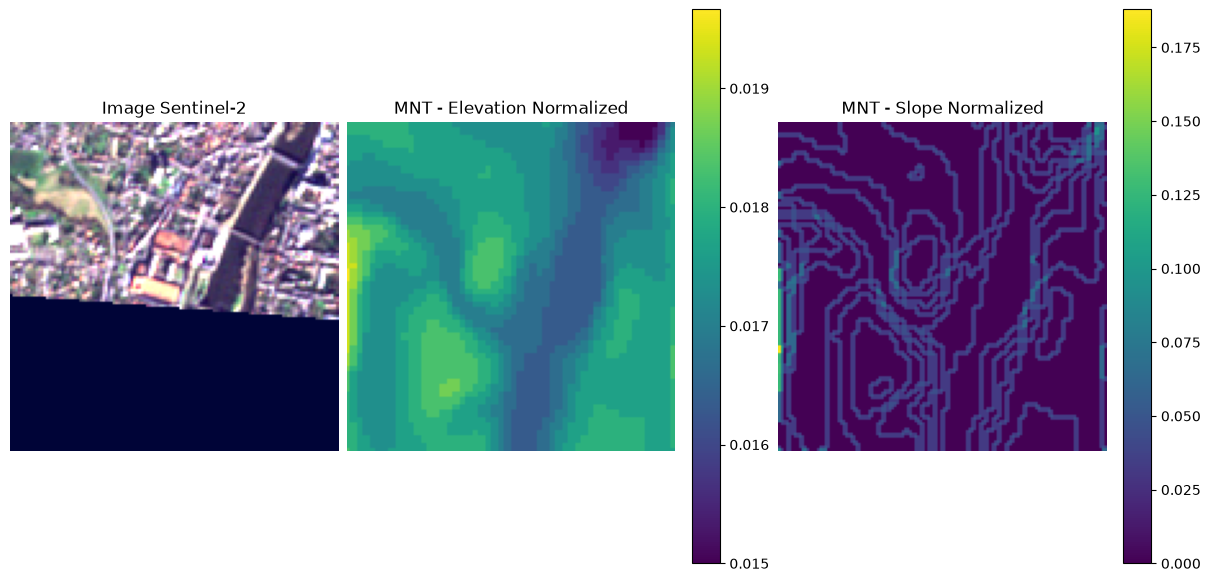

Longitude normalized :tensor([[0.3428, 0.3428, 0.3428,  ..., 0.3428, 0.3428, 0.3428],
        [0.3428, 0.3428, 0.3428,  ..., 0.3428, 0.3428, 0.3428],
        [0.3428, 0.3428, 0.3428,  ..., 0.3428, 0.3428, 0.3428],
        ...,
        [0.3438, 0.3438, 0.3438,  ..., 0.3438, 0.3438, 0.3438],
        [0.3438, 0.3438, 0.3438,  ..., 0.3438, 0.3438, 0.3438],
        [0.3439, 0.3439, 0.3439,  ..., 0.3439, 0.3439, 0.3439]])
Latitude normalized :tensor([[0.5318, 0.5318, 0.5318,  ..., 0.5318, 0.5318, 0.5318],
        [0.5318, 0.5318, 0.5318,  ..., 0.5318, 0.5318, 0.5318],
        [0.5318, 0.5318, 0.5318,  ..., 0.5318, 0.5318, 0.5318],
        ...,
        [0.5308, 0.5308, 0.5308,  ..., 0.5308, 0.5308, 0.5308],
        [0.5308, 0.5308, 0.5308,  ..., 0.5308, 0.5308, 0.5308],
        [0.5308, 0.5308, 0.5308,  ..., 0.5308, 0.5308, 0.5308]])


In [112]:
# Geodatas (slopes and elevation)
plot_functions.plot_geodatas(s2=inputs[0], geodatas=inputs[3], s2_timestep=1)

print(f"Longitude normalized :{inputs[3][0]}\nLatitude normalized :{inputs[3][1]}")

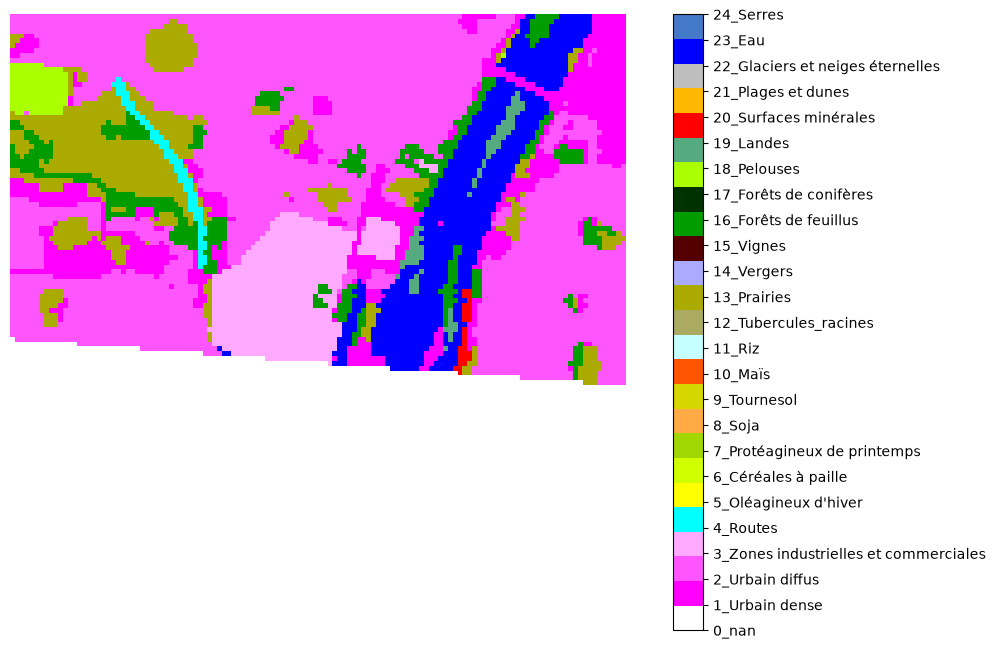

In [113]:
# Label
plot_functions.plot_label(label)